In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = load_diabetes()

In [3]:
X = data.data
y = data.target

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
scaler = StandardScaler()

In [6]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
y_mean = y_train.mean()
y_std = y_train.std()
y_train_scaled = (y_train - y_mean) / y_std
X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

In [8]:
def train_model(X, y, alpha=0.01, epochs=10000, regularization=None, lam=0.01, l1_ratio=0.5):
    m, n = X.shape
    weights = np.zeros(n)
    for i in range(epochs):
        predictions = X @ weights
        error = predictions - y
        gradient = (2 / m) * (X.T @ error)
        if regularization == "L1":
            gradient[1:] += (lam / m) * np.sign(weights[1:])
        elif regularization == "L2":
            gradient[1:] += (2 * lam / m) * weights[1:]
        elif regularization == "ElasticNet":
            gradient[1:] += (lam * l1_ratio / m) * np.sign(weights[1:])
            gradient[1:] += (2 * lam * (1 - l1_ratio) / m) * weights[1:]
        weights -= alpha * gradient
    return weights

In [9]:
models = {"Linear Regression": None, "L1 Regularization": "L1", "L2 Regularization": "L2", "ElasticNet": "ElasticNet"}
results = {}
for name, reg in models.items():
    weights = train_model(X_train, y_train_scaled, alpha=0.01, epochs=10000, regularization=reg, lam=0.01, l1_ratio=0.5)
    predictions = X_test @ weights
    predictions = predictions * y_std + y_mean
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results[name] = r2
    print("\n", name)
    print("MSE:", mse)
    print("R2 Score:", r2)


 Linear Regression
MSE: 2895.2971747991887
R2 Score: 0.45352694444627295

 L1 Regularization
MSE: 2895.149112633593
R2 Score: 0.45355489044944985

 L2 Regularization
MSE: 2895.2375083830266
R2 Score: 0.4535382061879132

 ElasticNet
MSE: 2895.1933140225497
R2 Score: 0.45354654765538605


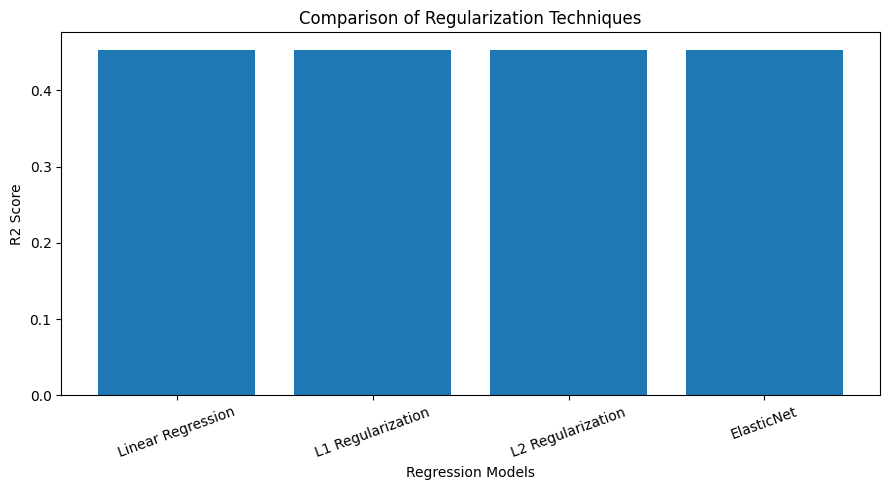

In [10]:
plt.figure(figsize=(9, 5))
plt.bar(results.keys(), results.values())
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.title("Comparison of Regularization Techniques")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()